# Centroiding profile spectra

Recover peak positions from an artificial profile-mode spectrum.

Centroiding converts multiple intensity measurements around one peak into a single representative m/z and intensity. Here the two Gaussian centres are known, so absolute mass error can be measured directly.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from peptide_methods import gaussian
from pyopenms import MSSpectrum, PeakPickerHiRes

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

centroids [400.   400.85]
absolute errors (mDa) [0. 0.]


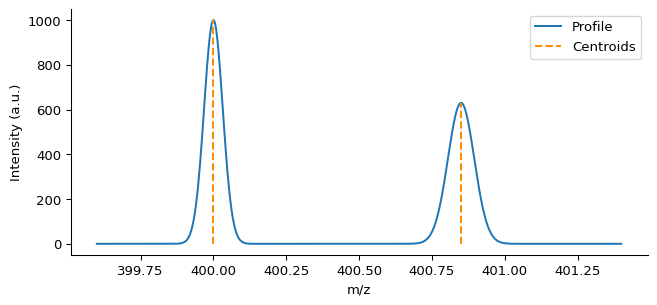

In [2]:
x = np.linspace(399.6, 401.4, 901)
truth = np.array([400.0, 400.85])
signal = 1000 * gaussian(x, truth[0], 0.032) + 630 * gaussian(x, truth[1], 0.045)
s = MSSpectrum()
s.set_peaks((x, signal))
out = MSSpectrum()
PeakPickerHiRes().pick(s, out)
mz, ints = out.get_peaks()
keep = ints > 30
mz = mz[keep]
ints = ints[keep]
assert len(mz) == 2 and np.max(abs(mz - truth)) < 0.003
print("centroids", np.round(mz, 5))
print("absolute errors (mDa)", np.round(1000 * np.abs(mz - truth), 3))
fig, ax = plt.subplots(figsize=(6.8, 3.1), constrained_layout=True)
ax.plot(x, signal, label="Profile")
ax.vlines(mz, 0, ints, color="darkorange", ls="--", label="Centroids")
ax.set(xlabel="m/z", ylabel="Intensity (a.u.)")
ax.legend()
plt.show()

## Interpreting the result

The stated errors refer to two resolved noiseless peaks. Overlapping peaks pose a different evaluation problem.

## Exercise

Move the second centre towards the first and find where the peak count changes.

## References

[OpenMS, centroiding and peak picking](https://pyopenms.readthedocs.io/en/latest/user_guide/peak_picking.html)